# Project: Segmentation of Cloudy Regions

## Project Introduction / Background

Clouds play a crucial role in the Earth’s climate system by influencing energy balance and weather patterns. However, their complex structures and organization make them difficult to represent accurately in climate models. Understanding different cloud patterns can help scientists improve climate predictions and reduce uncertainties in future climate projections.

In this project, we aim to use satellite images and machine learning techniques to classify and identify different cloud organization patterns. By accurately detecting cloud types and their spatial distribution, this work can contribute to a better understanding of atmospheric processes and support the development of more reliable climate models.

## Step 1: Exploratory Data Analysis (EDA) and Data Understanding

### Step 1.0: Environment Setup

This section imports the required Python libraries used throughout the exploratory data analysis. These libraries support data manipulation, visualization, image processing, and statistical analysis.

In [2]:
import os
from PIL import Image

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline

import albumentations as albu

### Step 1.1 : Dataset structure 

In this step, we explore the dataset structure and understand the training data before modeling.

The dataset contains four main files:

- `train.csv`: Contains image annotations, cloud categories, and segmentation masks encoded using Run-Length Encoding (RLE). This is the main dataset used for exploration.
- `train_images/`: Contains the corresponding satellite images used for visualization.
- `test_images/`: Contains unlabeled images that will be used later for prediction.
- `sample_submission.csv`: Provides the required format for the final submission.

In [3]:
path = '/home/ubuntu/Cloud_Project/understanding_cloud_organization'
os.listdir(path)

['train_images', 'sample_submission.csv', 'test_images', 'train.csv']

In [4]:
# Load training dataset
train = pd.read_csv(f'{path}/train.csv')

# Dataset dimensions
display(train.shape)

print("-" * 100)

# First rows of the dataset
display(train.head())

print("-" * 100)

# Dataset information
train.info()

(22184, 2)

----------------------------------------------------------------------------------------------------


,Image_Label,EncodedPixels
0,0011165.jpg_Fish,20056 257 20440 257 20824 257 21208 257 21592 ...
1,0011165.jpg_Flower,102135 1 102245 275 102629 275 103013 275 1033...
2,0011165.jpg_Gravel,NaN
3,0011165.jpg_Sugar,NaN
4,002be4f.jpg_Fish,17668 241 18051 242 18435 242 18819 242 19203 ...


----------------------------------------------------------------------------------------------------
<class 'pandas.DataFrame'>
RangeIndex: 22184 entries, 0 to 22183
Data columns (total 2 columns):
 #   Column         Non-Null Count  Dtype
---  ------         --------------  -----
 0   Image_Label    22184 non-null  str  
 1   EncodedPixels  11836 non-null  str  
dtypes: str(2)
memory usage: 346.8 KB


<div style="background-color:#1976D2; color:white; padding:12px; border-radius:5px;">
<b>Dataset Size and Structure</b>

The training dataset contains **22,184 annotation records** and **2 columns**:

- `Image_Label`: Contains the image name and the corresponding cloud type.
- `EncodedPixels`: Contains the segmentation mask information.

The dataset contains **11,836 available segmentation masks**, while the remaining records have missing values in the `EncodedPixels` column. These missing values indicate that the corresponding cloud type is not present in the image.
</div>

### Step 1.2: Image-Label Decomposition and Mask Availability Analysis

The `Image_Label` column combines two important pieces of information: the image identifier and the corresponding cloud category. Separating these components allows independent analysis of image-level information and cloud-type labels. In addition, the availability of segmentation masks is investigated through the `EncodedPixels` column. 

In [5]:
# Extract image ID and cloud category from Image_Label
train[["Image_id", "Cloud_Type"]] = train["Image_Label"].str.split("_", expand=True)

# Keep only required columns
train = train[["Image_id", "Cloud_Type", "EncodedPixels"]]

display(train.head())

print("-" * 100)

# Cloud category distribution
cloud_distribution = pd.DataFrame({
    "All_Records": train["Cloud_Type"].value_counts(),
    "Records_with_Masks": (
        train[train["EncodedPixels"].notna()]["Cloud_Type"]
        .value_counts()
    )
}).fillna(0)

display(cloud_distribution)

print("-" * 100)

# Mask availability analysis
mask_availability = pd.DataFrame({
    "Mask_Status": ["Available", "Missing"],
    "Count": [
        train["EncodedPixels"].notna().sum(),
        train["EncodedPixels"].isna().sum()
    ],
    "Percentage (%)": [
        round(train["EncodedPixels"].notna().mean() * 100, 2),
        round(train["EncodedPixels"].isna().mean() * 100, 2)
    ]
})

display(mask_availability)

,Image_id,Cloud_Type,EncodedPixels
0,0011165.jpg,Fish,20056 257 20440 257 20824 257 21208 257 21592 ...
1,0011165.jpg,Flower,102135 1 102245 275 102629 275 103013 275 1033...
2,0011165.jpg,Gravel,NaN
3,0011165.jpg,Sugar,NaN
4,002be4f.jpg,Fish,17668 241 18051 242 18435 242 18819 242 19203 ...


----------------------------------------------------------------------------------------------------


,All_Records,Records_with_Masks
Cloud_Type,,
Fish,5546,2781
Flower,5546,2365
Gravel,5546,2939
Sugar,5546,3751


----------------------------------------------------------------------------------------------------


,Mask_Status,Count,Percentage (%)
0,Available,11836,53.35
1,Missing,10348,46.65


<div style="background-color:#1976D2; color:white; padding:12px; border-radius:5px;">
The `Image_Label` column was separated into two independent features: the image identifier and the corresponding cloud category. The dataset contains four cloud types: <b>Fish, Flower, Gravel, and Sugar</b>, with one annotation record assigned to each cloud type for every image.

Approximately <b>53.35%</b> of the image-label pairs contain segmentation masks. The remaining records have missing values in `EncodedPixels`, which indicate the absence of the corresponding cloud type rather than missing or corrupted data. Therefore, these values are meaningful and should be preserved, as they provide useful information about images in which the corresponding cloud type is absent.

Although the annotation structure is balanced across the four cloud categories, the distribution of available segmentation masks is imbalanced, with <b>Sugar</b> being the most frequent cloud type and <b>Flower</b> the least represented category.
</div>

To provide a visual representation of the cloud category distribution among available segmentation masks, a pie chart was used. This visualization helps to identify the relative contribution of each cloud type and to assess the presence of class imbalance in the annotated masks.

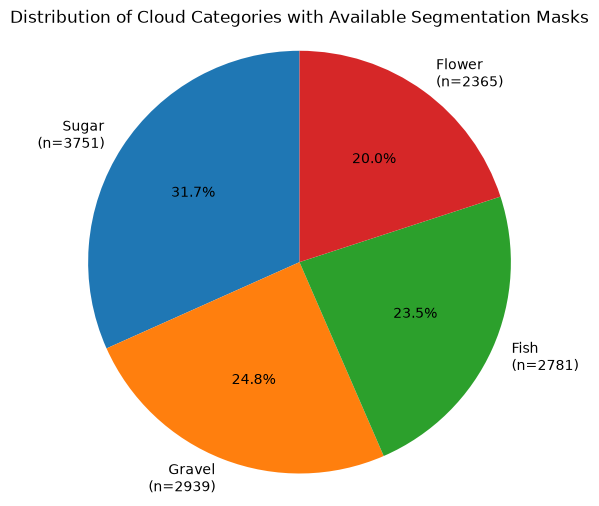

In [6]:
cloud_counts = train[train["EncodedPixels"].notna()]["Cloud_Type"].value_counts()

plt.figure(figsize=(6,6))

plt.pie(
    cloud_counts,
    labels=[
        f"{label}\n(n={count})" 
        for label, count in zip(cloud_counts.index, cloud_counts.values)
    ],
    autopct="%1.1f%%",
    startangle=90
)

plt.title("Distribution of Cloud Categories with Available Segmentation Masks")
plt.axis("equal")

plt.show()

<div style="background-color:#1976D2; color:white; padding:12px; border-radius:5px;">
 The pie chart confirms an imbalanced distribution of cloud categories among the available segmentation masks, with Sugar representing the largest share and Flower the smallest.
</div>

### Step 1.3 : Image-Level Mask Distribution

Each satellite image may contain one or more cloud categories. In this section, we analyze the number of segmentation masks associated with each image to better understand the complexity of the dataset and the distribution of cloud patterns across images.

In [7]:
# Number of unique images
print(f"The dataset contains {train['Image_id'].nunique():,} unique images.")

# Number of available masks per image
mask_per_image = (
    train.groupby("Image_id")["EncodedPixels"]
    .apply(lambda x: x.notna().sum())
)

display(mask_per_image.head())

# Check images without any available masks
print(f"The dataset contains {(mask_per_image == 0).sum()} images with no available masks.")

The dataset contains 5,546 unique images.


Image_id
0011165.jpg    2
002be4f.jpg    3
0031ae9.jpg    3
0035239.jpg    2
003994e.jpg    3
Name: EncodedPixels, dtype: int64

The dataset contains 0 images with no available masks.


<div style="background-color:#1976D2; color:white; padding:12px; border-radius:5px;">
The analysis shows that <b>all images contain at least one available segmentation mask</b>, confirming that every image includes at least one annotated cloud category.
</div>

To visualize the distribution of the number of available segmentation masks per image, a bar plot was generated. This visualization provides a clearer overview of how cloud categories are distributed across individual satellite images.

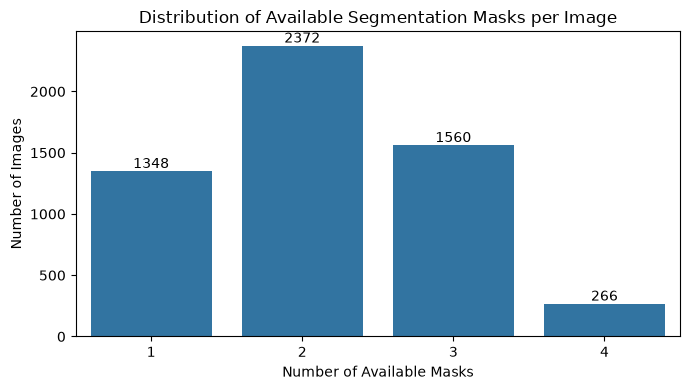

In [8]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(7,4))

ax = sns.countplot(
    x=mask_per_image,
    order=sorted(mask_per_image.unique())
)

# Add count labels on bars
for container in ax.containers:
    ax.bar_label(container, fontsize=10)

plt.title("Distribution of Available Segmentation Masks per Image")
plt.xlabel("Number of Available Masks")
plt.ylabel("Number of Images")

plt.tight_layout()
plt.show()

<div style="background-color:#1976D2; color:white; padding:12px; border-radius:5px;">
The distribution of available masks per image shows that most satellite images contain multiple cloud categories. This indicates that different cloud formations frequently coexist within the same image, increasing the complexity of the segmentation task. However, images containing all four cloud categories are relatively rare, with only <b>266 images</b> having four available masks. This highlights that although multi-cloud patterns are common, the full combination of all cloud types occurs less frequently.
</div>

### Step 1.4: Image Exploration and Visualization

In [9]:
image_sizes = []

image_folder = f"{path}/train_images"

for img_name in os.listdir(image_folder):
    img_path = os.path.join(image_folder, img_name)  #/home/ubuntu/Cloud_Project/train_images/0011165.jpg
    img = Image.open(img_path)
    image_sizes.append(img.size)

unique_sizes = set(image_sizes)

print(f"Unique image resolutions found: {unique_sizes}")

if len(unique_sizes) == 1:
    size = list(unique_sizes)[0]
    print(f"All training images have the same resolution of {size[0]} × {size[1]} pixels.")
else:
    print("The dataset contains images with different resolutions.")

Unique image resolutions found: {(576, 384)}
All training images have the same resolution of 576 × 384 pixels.


In [10]:
print(f"Image mode: {img.mode}")

Image mode: RGB


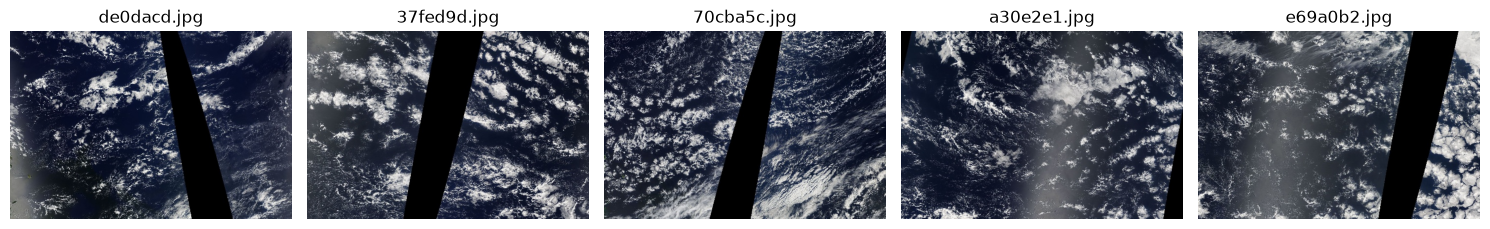

In [11]:
image_folder = f"{path}/train_images"

sample_images = os.listdir(image_folder)[:5]

plt.figure(figsize=(15,8))

for i, img_name in enumerate(sample_images):
    img = Image.open(os.path.join(image_folder, img_name))

    plt.subplot(1,5,i+1)
    plt.imshow(img)
    plt.title(img_name)
    plt.axis("off") #Hide axis

plt.tight_layout()
plt.show()


Several satellite images were visualized to confirm the input image characteristics and observe different cloud formations.

### Step 1.5 — Segmentation Mask Exploration

The segmentation annotations are provided in Run-Length Encoding (RLE) format. To analyze and visualize the cloud regions, the RLE annotations were decoded into binary masks.
This step allows us to reconstruct the spatial location of each cloud category and verify that the segmentation annotations correctly represent the cloud regions in the satellite images.

In [12]:
def rle_decode(rle, shape=(384, 576)):
    
    mask = np.zeros(shape[0] * shape[1], dtype=np.uint8)

    if pd.isna(rle):
        return mask.reshape(shape)

    numbers = list(map(int, rle.split()))

    starts = numbers[0::2]
    lengths = numbers[1::2]

    for start, length in zip(starts, lengths):
        start -= 1
        mask[start:start+length] = 1

    return mask.reshape(shape)

To visually validate the decoded segmentation masks, the reconstructed masks were overlaid on the original satellite images.
This visualization helps confirm that the masks are correctly aligned with the corresponding cloud regions and provides a better understanding of the spatial distribution of different cloud formations.

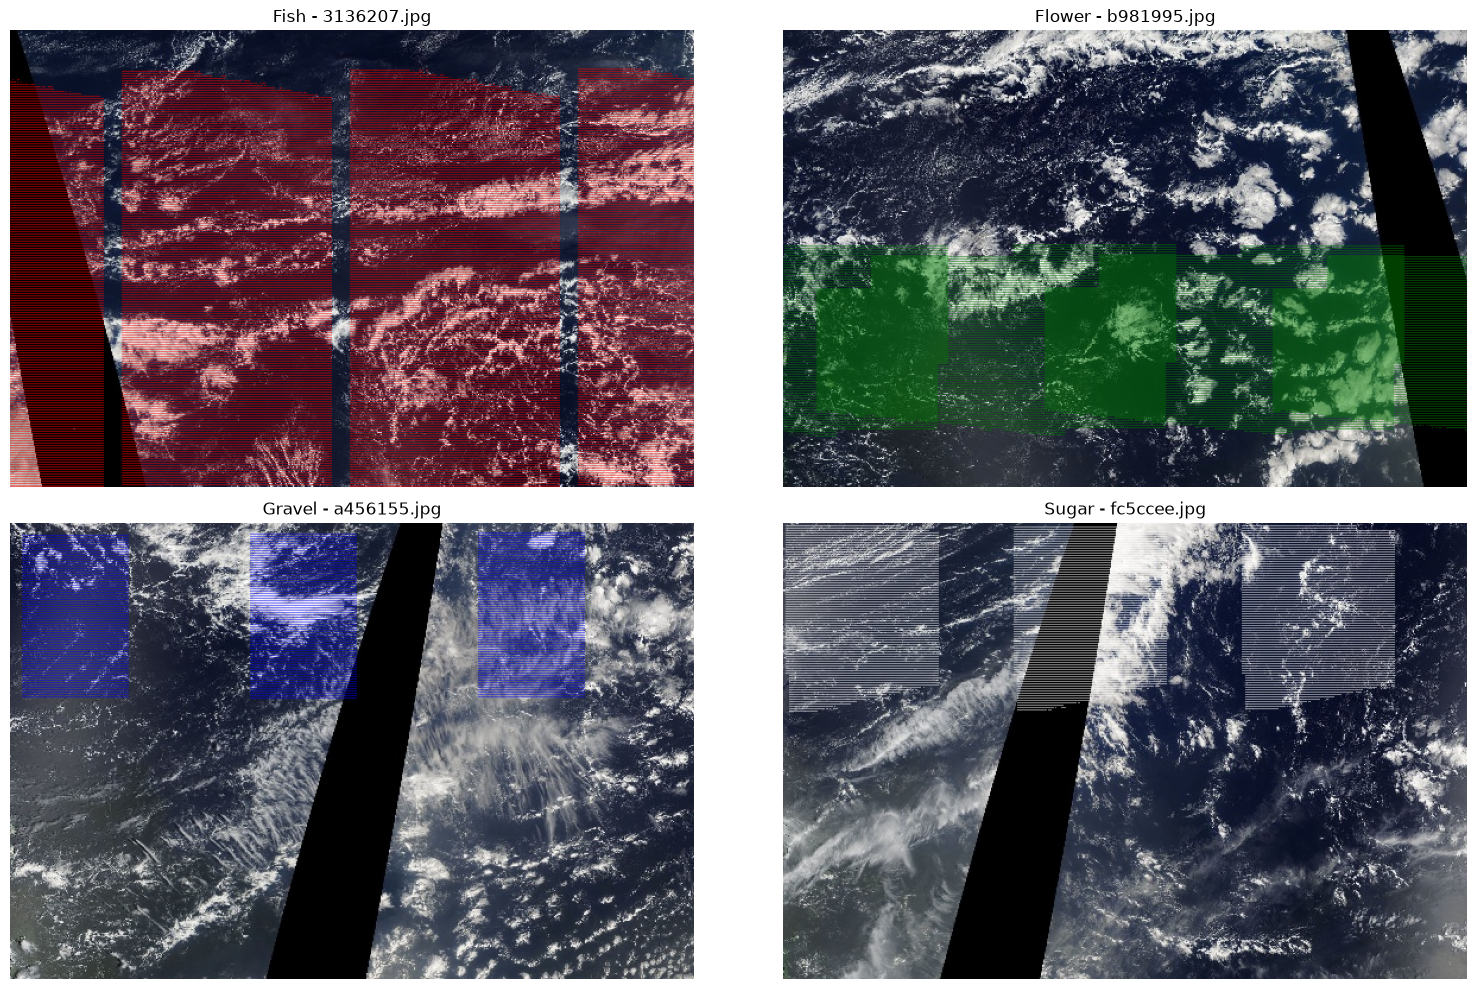

In [13]:
cloud_colors = {
    "Fish": "red",
    "Flower": "green",
    "Gravel": "blue",
    "Sugar": "white"
}

cloud_types = ["Fish", "Flower", "Gravel", "Sugar"]

samples = []

for cloud in cloud_types:
    sample = train[
        (train["Cloud_Type"] == cloud) &
        (train["EncodedPixels"].notna())
    ].sample(1).iloc[0]  #.sample(1, random_state=42) 
    
    samples.append(sample)


plt.figure(figsize=(16, 10))

for i, sample in enumerate(samples):

    # Load original image
    img = Image.open(
        f"{path}/train_images/{sample['Image_id']}"
    )

    # Decode RLE mask
    mask = rle_decode(sample["EncodedPixels"])

    plt.subplot(2, 2, i+1)

    # Show original image
    plt.imshow(img)

    # Create colored mask
    colored_mask = np.zeros(
        (*mask.shape, 4)  #Height × Width × RGBA
    )

    color = cloud_colors[sample["Cloud_Type"]]

    colored_mask[mask == 1] = (
        plt.cm.colors.to_rgba(color)
    )

    # Overlay colored mask
    plt.imshow(
        colored_mask,
        alpha=0.5
    )

    plt.title(
        f"{sample['Cloud_Type']} - {sample['Image_id']}"
    )

    plt.axis("off")


plt.tight_layout()
plt.show()

<div style="background-color:#1976D2; color:white; padding:12px; border-radius:5px;">
The overlay visualization confirmed that the reconstructed masks were correctly aligned with the original satellite images and accurately represented the annotated cloud areas.
</div>

### Step 1-Summary

This exploratory data analysis provided a comprehensive understanding of the dataset structure, cloud category distribution, image characteristics, and segmentation annotations, highlighting the main challenges of the cloud segmentation task.

The analysis revealed that satellite images may contain multiple cloud formations, with the distribution of available segmentation masks varying across cloud categories. Missing values in `EncodedPixels` were identified as meaningful information, representing the absence of a specific cloud category rather than missing or corrupted annotations. Therefore, these values were preserved for further processing.

The provided RLE annotations were successfully decoded into binary segmentation masks. Both numerical analysis and visual validation confirmed that the reconstructed masks accurately represent the corresponding cloud regions within the satellite images.

Overall, the findings from this step provide a solid understanding of the dataset properties and annotation characteristics, serving as a foundation for the subsequent data preprocessing and cloud segmentation modeling stages.

## Step 2: Data Preparation

#### Step 2.1: Image Size Verification

Before applying any preprocessing operation, the image dimensions were analyzed to determine whether resizing was required.

In [14]:
image_folder = f"{path}/train_images"

image_sizes = []

for img_name in os.listdir(image_folder):
    img_path = os.path.join(image_folder, img_name)
    img = Image.open(img_path)
    image_sizes.append(img.size)

unique_sizes = set(image_sizes)

print("Unique image sizes:")
print(unique_sizes)

Unique image sizes:
{(576, 384)}


<div style="background-color:#1976D2; color:white; padding:12px; border-radius:5px;">
All training images have the same resolution of 576 × 384 pixels. Therefore, no additional resizing operation is required at this stage, as the dataset is already prepared with consistent image dimensions.
</div>

#### Step 2.2: Data Augmentation

Data augmentation was applied to increase the variability of the training data and improve the model's ability to generalize to unseen satellite images.

In [15]:
print(type(img))
print(type(mask))

<class 'PIL.JpegImagePlugin.JpegImageFile'>
<class 'numpy.ndarray'>


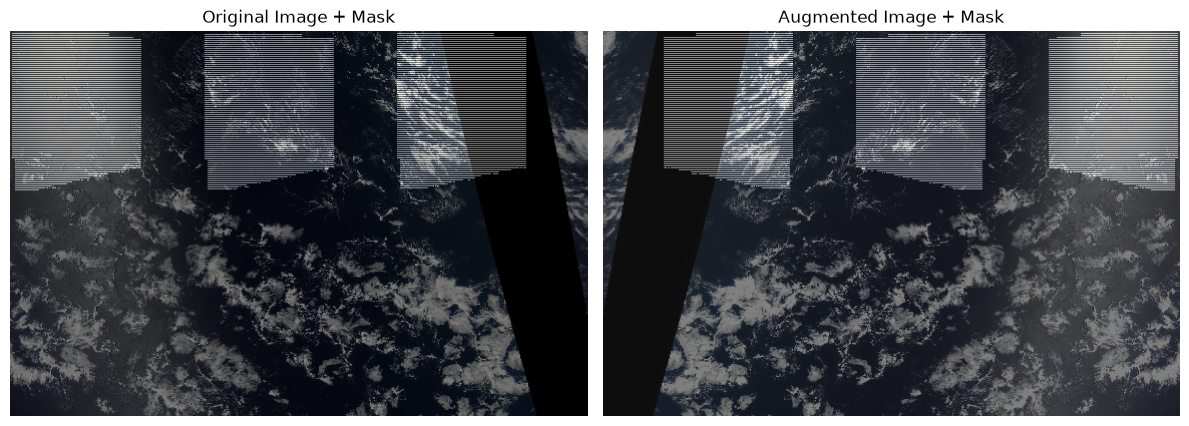

In [17]:
# Define augmentation pipeline
transform = albu.Compose([
    albu.HorizontalFlip(p=0.5),
    albu.VerticalFlip(p=0.5),
    albu.RandomRotate90(p=0.5),
    albu.RandomBrightnessContrast(p=0.3)
])


# Apply augmentation to image and mask
image = np.array(img)

augmented = transform(
    image=image,
    mask=mask
)


# Extract augmented image and mask
augmented_image = augmented["image"]
augmented_mask = augmented["mask"]


# Visualization: before and after augmentation

plt.figure(figsize=(12,5))


# Original image + mask
plt.subplot(1,2,1)

plt.imshow(image)
plt.imshow(mask, alpha=0.5, cmap="gray")

plt.title("Original Image + Mask")
plt.axis("off")


# Augmented image + mask
plt.subplot(1,2,2)

plt.imshow(augmented_image)
plt.imshow(augmented_mask, alpha=0.5, cmap="gray")

plt.title("Augmented Image + Mask")
plt.axis("off")


plt.tight_layout()
plt.show()

<div style="background-color:#1976D2; color:white; padding:12px; border-radius:5px;">
Since this is an image segmentation task, the same transformations were applied to both images and their corresponding masks to preserve their spatial alignment. Different augmentation techniques, including horizontal flipping, rotation, and brightness/contrast adjustment, were tested on sample images. The results were then visualized to confirm that the masks remained correctly aligned after transformation.
</div>